# Brain Tumor Detection Using Deep Learning
## Using TensorFlow, Keras | Models: EfficientNetV2 & InceptionV3

**Dataset:** Cranial MRI Scan Archive (4 classes — Glioma, Meningioma, No Tumor, Pituitary)

**Training Strategy:** Transfer Learning → Data Augmentation → Two-Stage Training (Feature Extraction + Fine-Tuning)

In [1]:
import os
import numpy as np
import pandas as pd
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2S, InceptionV3
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# ============ Configuration ============
CLASS_NAMES = ['glioma', 'meningioma', 'notumor', 'pituitary']
NUM_CLASSES = len(CLASS_NAMES)

# protita model er jonno official recommended input size use korchi
# EfficientNetV2S er default 300, InceptionV3 er default 299
EFF_IMG_SIZE = 300
INC_IMG_SIZE = 299

BATCH_SIZE = 32

# Two-Stage Training epochs
INITIAL_EPOCHS = 10     # Stage 1: shudhu classifier head train hobe
FINE_TUNE_EPOCHS = 10   # Stage 2: base model er uporer layers o train hobe

TRAIN_DIR = 'CranialMRI_ScanArchive/Training'
TEST_DIR = 'CranialMRI_ScanArchive/Testing'
MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Classes: {CLASS_NAMES}")
print(f"EfficientNetV2 Image Size: {EFF_IMG_SIZE}x{EFF_IMG_SIZE}")
print(f"InceptionV3 Image Size: {INC_IMG_SIZE}x{INC_IMG_SIZE}")
print(f"Training Strategy: {INITIAL_EPOCHS} epochs (frozen) + {FINE_TUNE_EPOCHS} epochs (fine-tune)")

TensorFlow Version: 2.21.0
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
EfficientNetV2 Image Size: 300x300
InceptionV3 Image Size: 299x299
Training Strategy: 10 epochs (frozen) + 10 epochs (fine-tune)


## Data Exploration & Visualization

In [3]:
# protita class e koto gulo image ache seta count korchi
train_counts = {}
test_counts = {}
for cls in CLASS_NAMES:
    train_path = os.path.join(TRAIN_DIR, cls)
    test_path = os.path.join(TEST_DIR, cls)
    train_counts[cls] = len(os.listdir(train_path)) if os.path.exists(train_path) else 0
    test_counts[cls] = len(os.listdir(test_path)) if os.path.exists(test_path) else 0

df_summary = pd.DataFrame({
    'Class': CLASS_NAMES,
    'Train': [train_counts[c] for c in CLASS_NAMES],
    'Test': [test_counts[c] for c in CLASS_NAMES]
})
df_summary['Total'] = df_summary['Train'] + df_summary['Test']
print(df_summary.to_string(index=False))
print(f"\nTotal Training Images: {df_summary['Train'].sum()}")
print(f"Total Testing Images: {df_summary['Test'].sum()}")

     Class  Train  Test  Total
    glioma   1400   400   1800
meningioma   1400   400   1800
   notumor   1400   400   1800
 pituitary   1400   400   1800

Total Training Images: 5600
Total Testing Images: 1600


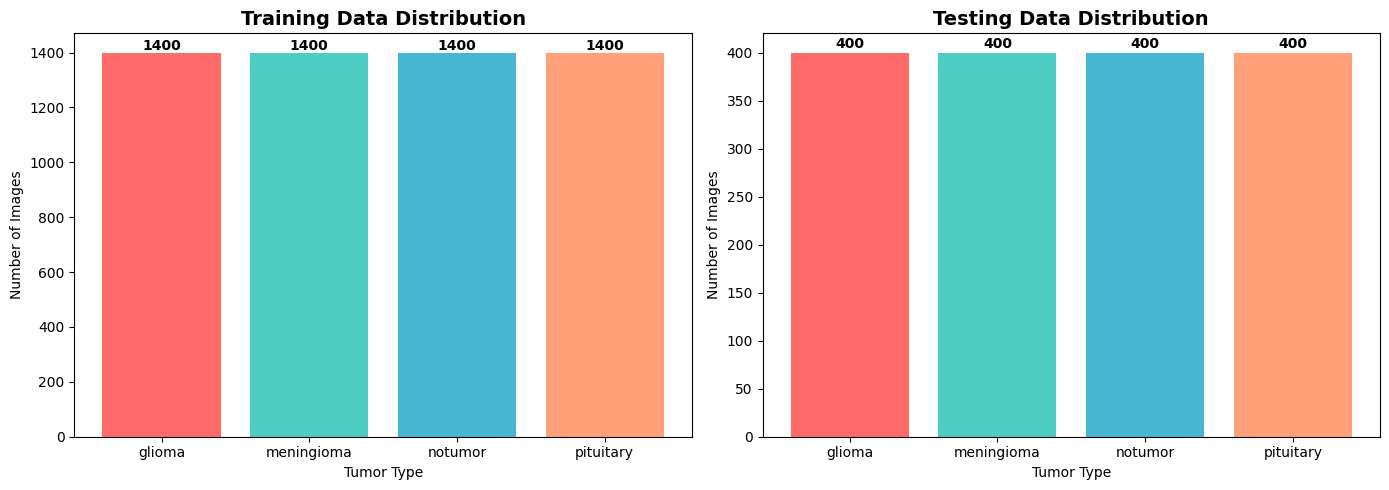

In [4]:
# Data Visualization: Training vs Testing Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

axes[0].bar(CLASS_NAMES, [train_counts[c] for c in CLASS_NAMES], color=colors)
axes[0].set_title('Training Data Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Tumor Type')
axes[0].set_ylabel('Number of Images')
for i, v in enumerate([train_counts[c] for c in CLASS_NAMES]):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

axes[1].bar(CLASS_NAMES, [test_counts[c] for c in CLASS_NAMES], color=colors)
axes[1].set_title('Testing Data Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tumor Type')
axes[1].set_ylabel('Number of Images')
for i, v in enumerate([test_counts[c] for c in CLASS_NAMES]):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

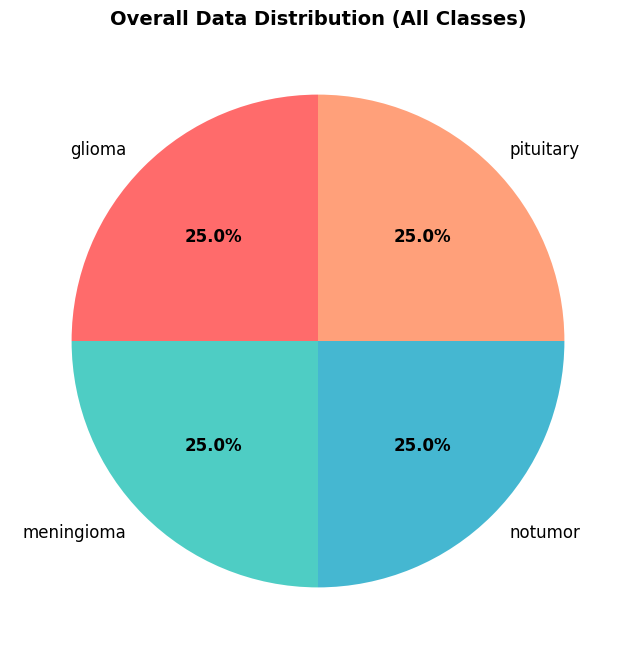

In [5]:
# Pie Chart: Overall Class Distribution
total_counts = [train_counts[c] + test_counts[c] for c in CLASS_NAMES]
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(total_counts, labels=CLASS_NAMES, autopct='%1.1f%%',
                                   colors=colors, startangle=90, textprops={'fontsize': 12})
for autotext in autotexts:
    autotext.set_fontweight('bold')
ax.set_title('Overall Data Distribution (All Classes)', fontsize=14, fontweight='bold')
plt.show()

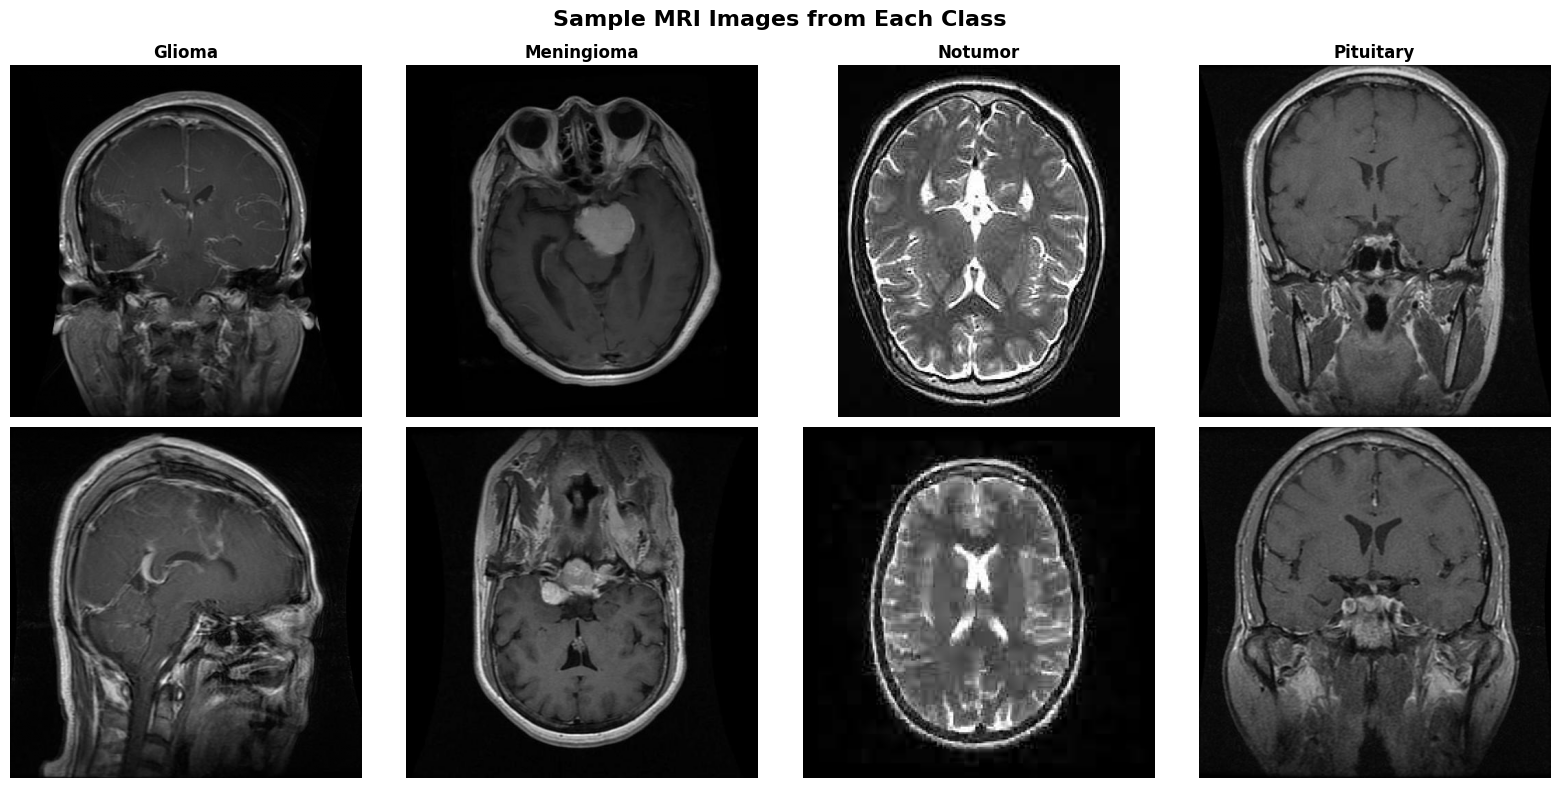

In [6]:
# Display Sample MRI Images from Each Class
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample MRI Images from Each Class', fontsize=16, fontweight='bold')

for idx, cls in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TRAIN_DIR, cls)
    images = os.listdir(class_dir)

    # Top row
    img_path = os.path.join(class_dir, images[0])
    img = Image.open(img_path)
    axes[0, idx].imshow(img, cmap='gray')
    axes[0, idx].set_title(cls.capitalize(), fontsize=12, fontweight='bold')
    axes[0, idx].axis('off')

    # Bottom row
    img_path2 = os.path.join(class_dir, images[1])
    img2 = Image.open(img_path2)
    axes[1, idx].imshow(img2, cmap='gray')
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()

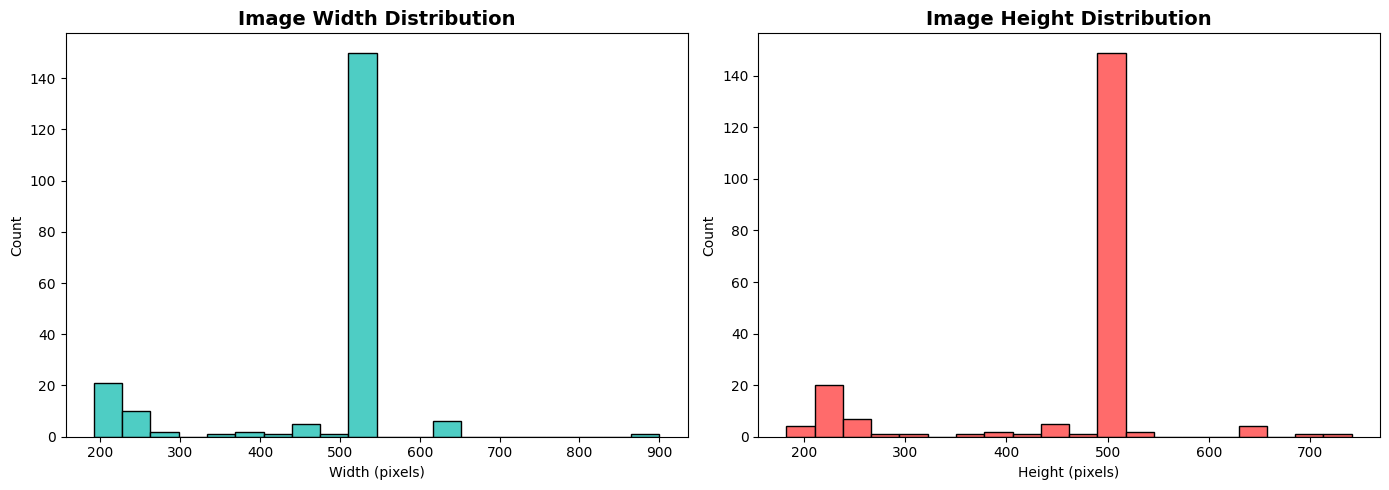

Average Width: 466, Average Height: 466


In [7]:
# Image Size Analysis — original MRI gulo ki size e ache?
widths = []
heights = []
for cls in CLASS_NAMES:
    class_dir = os.path.join(TRAIN_DIR, cls)
    for img_name in os.listdir(class_dir)[:50]:
        img_path = os.path.join(class_dir, img_name)
        try:
            img = Image.open(img_path)
            w, h = img.size
            widths.append(w)
            heights.append(h)
        except:
            pass

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(widths, bins=20, color='#4ECDC4', edgecolor='black')
axes[0].set_title('Image Width Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Width (pixels)')
axes[0].set_ylabel('Count')

axes[1].hist(heights, bins=20, color='#FF6B6B', edgecolor='black')
axes[1].set_title('Image Height Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Height (pixels)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()
print(f"Average Width: {np.mean(widths):.0f}, Average Height: {np.mean(heights):.0f}")

## Dataset Preparation

Training data theke 80% training er jonno ar 20% validation er jonno use korbo. Testing folder ta completely alada (hold-out) rakhchi — eta shudhu final evaluation e ekbar use hobe. Eta kora hocche jate model er actual generalization performance bujha jay.

In [9]:
# Dataset loading function — protita model er jonno alada image size
# Training folder thekei 80/20 split kore train ar validation set toiri korchi
# Testing folder completely unseen hold-out set hisebe rakhchi
def load_datasets(img_size):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR,
        validation_split=0.2,
        subset='training',
        seed=42,
        image_size=(img_size, img_size),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        class_names=CLASS_NAMES,
        shuffle=True
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR,
        validation_split=0.2,
        subset='validation',
        seed=42,
        image_size=(img_size, img_size),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        class_names=CLASS_NAMES,
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR,
        image_size=(img_size, img_size),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        class_names=CLASS_NAMES,
        shuffle=False
    )

    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

    return train_ds, val_ds, test_ds

# EfficientNetV2 er jonno 300x300 dataset
print("Loading EfficientNetV2 datasets (300x300)...")
eff_train_ds, eff_val_ds, eff_test_ds = load_datasets(EFF_IMG_SIZE)

# InceptionV3 er jonno 299x299 dataset
print("\nLoading InceptionV3 datasets (299x299)...")
inc_train_ds, inc_val_ds, inc_test_ds = load_datasets(INC_IMG_SIZE)

Loading EfficientNetV2 datasets (300x300)...
Found 5600 files belonging to 4 classes.


Using 4480 files for training.


Found 5600 files belonging to 4 classes.


Using 1120 files for validation.


Found 1600 files belonging to 4 classes.



Loading InceptionV3 datasets (299x299)...


Found 5600 files belonging to 4 classes.


Using 4480 files for training.


Found 5600 files belonging to 4 classes.


Using 1120 files for validation.


Found 1600 files belonging to 4 classes.


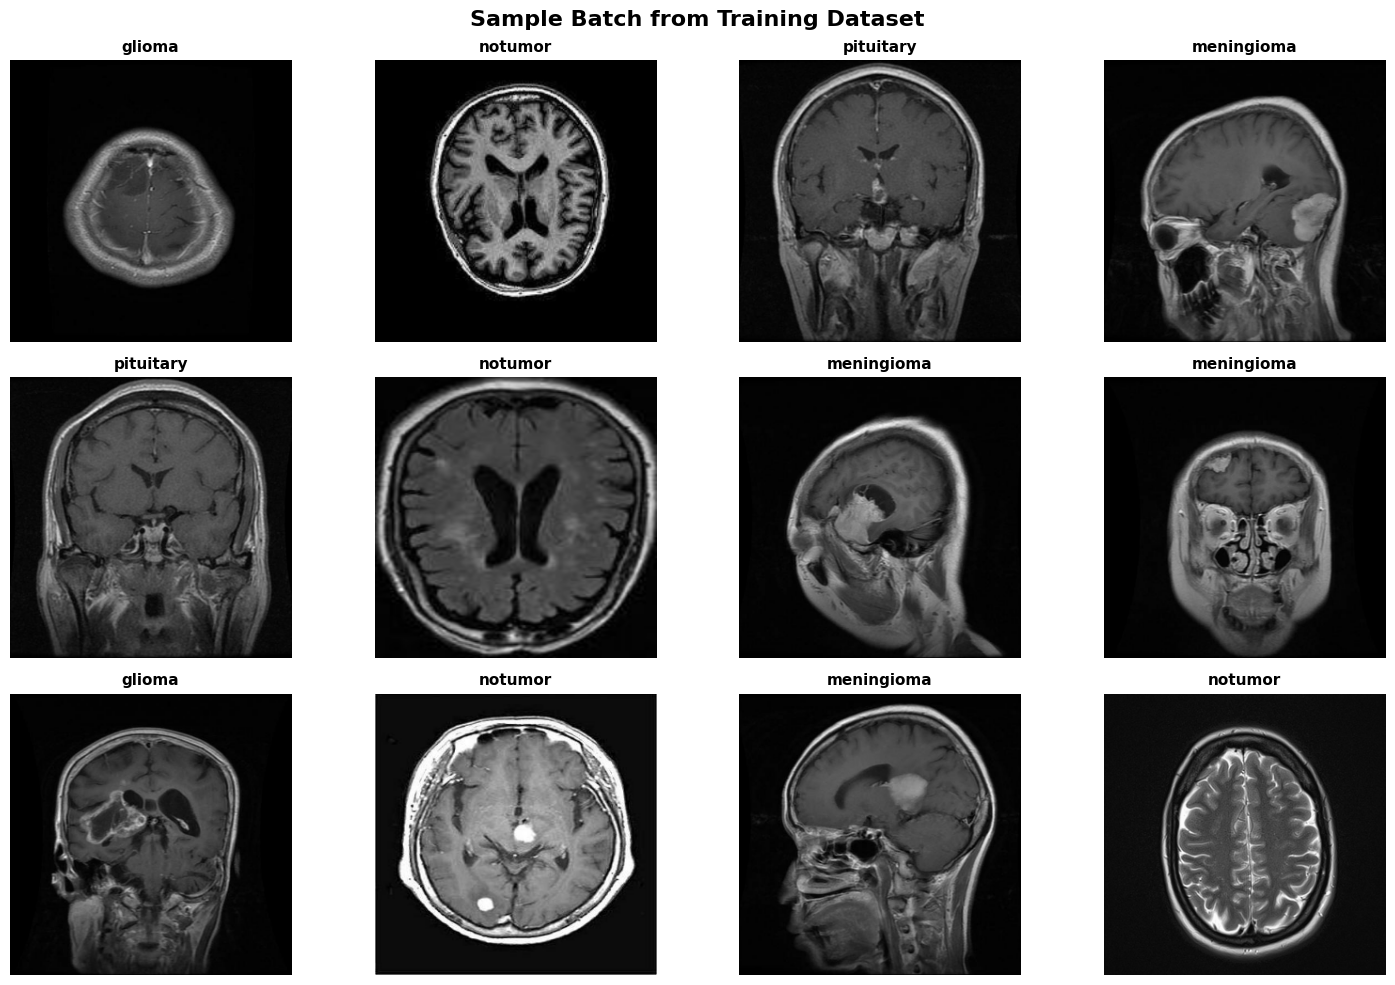

In [10]:
# Visualize a Batch of Training Images
plt.figure(figsize=(15, 10))
for images, labels in eff_train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = np.argmax(labels[i])
        plt.title(CLASS_NAMES[label_idx], fontsize=11, fontweight='bold')
        plt.axis("off")
plt.suptitle('Sample Batch from Training Dataset', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Data Augmentation

MRI scan gulo ke randomly flip, rotate, zoom ar contrast change kore training data ke diversify kora hocche. Eta model ke overfitting theke bachay ar notun patient er scan e better perform korte help kore. Augmentation shudhu training er somoy apply hoy, validation/testing e hoy na.

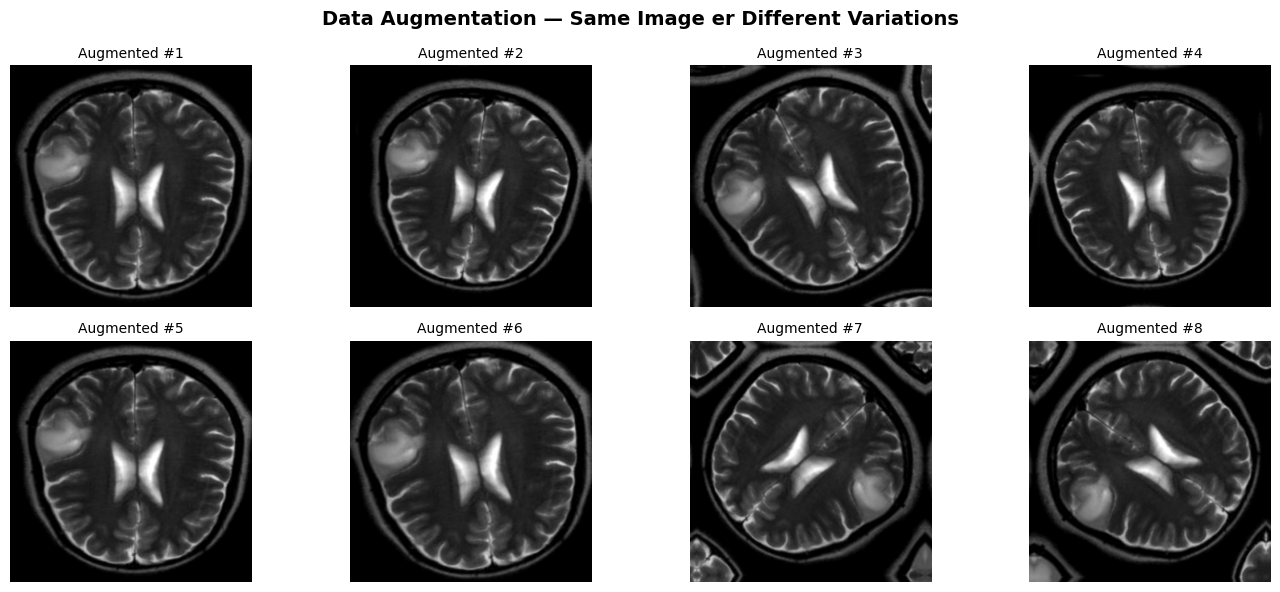

Data Augmentation visualization complete!


In [12]:
# Data Augmentation — ei layer gulo model er bhitore thakbe
# training er somoy automatically augment korbe, inference e kichui korbe na

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='data_augmentation')

# dekhchi augmentation apply korle ki hoy
plt.figure(figsize=(14, 6))
for images, _ in eff_train_ds.take(1):
    sample_img = images[0]
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        augmented = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
        plt.imshow(augmented[0].numpy().astype("uint8"))
        plt.title(f"Augmented #{i+1}", fontsize=10)
        plt.axis("off")
plt.suptitle('Data Augmentation — Same Image er Different Variations', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("Data Augmentation visualization complete!")

## Model Architecture

Duita model define korchi — EfficientNetV2S ar InceptionV3. Protita model er structure:

1. **Input Layer** → model er designated image size
2. **Data Augmentation** → Random flip, rotation, zoom, contrast
3. **Preprocessing** (InceptionV3 er jonno pixel values ke [-1, 1] e scale kora)
4. **Pre-trained Base Model** (ImageNet weights) → Feature Extractor hisebe kaj kore
5. **Global Average Pooling** → Feature map ke single vector e convert kore
6. **Dense → BatchNorm → ReLU → Dropout** → Classification head
7. **Softmax Output** → 4 class er probability

In [14]:
# ========== Model 1: EfficientNetV2S ==========
def create_efficientnet_model():
    base_model = EfficientNetV2S(
        input_shape=(EFF_IMG_SIZE, EFF_IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Stage 1 e freeze thakbe

    # augmentation layer define
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name='eff_augmentation')

    model = models.Sequential([
        layers.InputLayer(input_shape=(EFF_IMG_SIZE, EFF_IMG_SIZE, 3)),
        aug,
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, use_bias=False),     # bias=False karon porer BatchNorm e bias handle hoy
        layers.BatchNormalization(),            # BN aage, activation pore — correct order
        layers.Activation('relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model


# ========== Model 2: InceptionV3 ==========
def create_inception_model():
    base_model = InceptionV3(
        input_shape=(INC_IMG_SIZE, INC_IMG_SIZE, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False

    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name='inc_augmentation')

    model = models.Sequential([
        layers.InputLayer(input_shape=(INC_IMG_SIZE, INC_IMG_SIZE, 3)),
        aug,
        layers.Rescaling(1./127.5, offset=-1),  # InceptionV3 er jonno [-1, 1] range e scale
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model


print("Model architectures defined successfully!")
print(f"EfficientNetV2 input: {EFF_IMG_SIZE}x{EFF_IMG_SIZE}")
print(f"InceptionV3 input: {INC_IMG_SIZE}x{INC_IMG_SIZE}")

Model architectures defined successfully!
EfficientNetV2 input: 300x300
InceptionV3 input: 299x299


## Model Training (Two-Stage Transfer Learning)

### Training Strategy:
- **Stage 1 — Feature Extraction:** Base model er shob layer freeze kore shudhu uporer classification head train korchi. Eta head er weights ke properly initialize kore.
- **Stage 2 — Fine-Tuning:** Base model er last 40 ta layer unfreeze kore khub kom learning rate (1e-5) diye aro train korchi. Eta model ke medical image er specific pattern shikhte help kore.

### Callbacks:
- **EarlyStopping** — validation loss na komle 5 epoch por training bondho kore dey
- **ModelCheckpoint** — shudhu best model save kore (validation loss onusare)
- **ReduceLROnPlateau** — stuck hole learning rate komaye dey

In [16]:
# ==================== EfficientNetV2 Training ====================

# ===== Stage 1: Feature Extraction (base model frozen) =====
print("=" * 60)
print("  EfficientNetV2 | Stage 1: Feature Extraction")
print("=" * 60)

eff_model, eff_base = create_efficientnet_model()

eff_callbacks_s1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.2,
        patience=3, min_lr=1e-7, verbose=1
    )
]

eff_history_s1 = eff_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=eff_callbacks_s1
)

s1_epochs = len(eff_history_s1.history['accuracy'])
print(f"\nStage 1 complete — {s1_epochs} epochs trained")
print(f"Stage 1 Val Accuracy: {eff_history_s1.history['val_accuracy'][-1]*100:.2f}%")

# ===== Stage 2: Fine-Tuning (last 40 layers unfreeze) =====
print("\n" + "=" * 60)
print("  EfficientNetV2 | Stage 2: Fine-Tuning")
print("=" * 60)

eff_base.trainable = True

# last 40 ta layer unfreeze, baki shob freeze
fine_tune_at = len(eff_base.layers) - 40
for layer in eff_base.layers[:fine_tune_at]:
    layer.trainable = False

trainable_count = sum(1 for l in eff_base.layers if l.trainable)
print(f"Base model total layers: {len(eff_base.layers)}")
print(f"Trainable layers (fine-tune): {trainable_count}")

# recompile with much lower learning rate — fine-tune e beshi LR dile
# pretrained weights noshto hoye jabe
eff_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

eff_callbacks_s2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(MODELS_DIR, 'efficientnet_v2_best.keras'),
        monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.2,
        patience=3, min_lr=1e-7, verbose=1
    )
]

eff_history_s2 = eff_model.fit(
    eff_train_ds,
    validation_data=eff_val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=eff_callbacks_s2
)

# final model save
eff_model.save(os.path.join(MODELS_DIR, 'efficientnet_v2_final.keras'))

# duita stage er history combine kori — plotting er jonno lagbe
eff_acc = eff_history_s1.history['accuracy'] + eff_history_s2.history['accuracy']
eff_val_acc = eff_history_s1.history['val_accuracy'] + eff_history_s2.history['val_accuracy']
eff_loss_hist = eff_history_s1.history['loss'] + eff_history_s2.history['loss']
eff_val_loss = eff_history_s1.history['val_loss'] + eff_history_s2.history['val_loss']

s2_epochs = len(eff_history_s2.history['accuracy'])
total = s1_epochs + s2_epochs
print(f"\n✅ EfficientNetV2 training complete!")
print(f"Total epochs: {total} ({s1_epochs} frozen + {s2_epochs} fine-tuned)")
print(f"Final Val Accuracy: {eff_val_acc[-1]*100:.2f}%")
print(f"Model saved to models/efficientnet_v2_final.keras")

  EfficientNetV2 | Stage 1: Feature Extraction


Epoch 1/10


  1/140 ━━━━━━━━━━━━━━━━━━━━ 37:59 16s/step - accuracy: 0.3438 - loss: 1.4476

  2/140 ━━━━━━━━━━━━━━━━━━━━ 7:56 3s/step - accuracy: 0.3828 - loss: 1.4107  

  3/140 ━━━━━━━━━━━━━━━━━━━━ 7:49 3s/step - accuracy: 0.4149 - loss: 1.3595

  4/140 ━━━━━━━━━━━━━━━━━━━━ 7:32 3s/step - accuracy: 0.4499 - loss: 1.2936

... (2,848 outputs left out)


Epoch 10: val_loss did not improve from 0.02030


140/140 ━━━━━━━━━━━━━━━━━━━━ 713s 5s/step - accuracy: 0.9406 - loss: 0.1647 - val_accuracy: 0.9946 - val_loss: 0.0225 - learning_rate: 2.0000e-06


Restoring model weights from the end of the best epoch: 9.



✅ EfficientNetV2 training complete!
Total epochs: 20 (10 frozen + 10 fine-tuned)
Final Val Accuracy: 99.46%
Model saved to models/efficientnet_v2_final.keras


In [17]:
# ==================== InceptionV3 Training ====================

# ===== Stage 1: Feature Extraction (base model frozen) =====
print("=" * 60)
print("  InceptionV3 | Stage 1: Feature Extraction")
print("=" * 60)

inception_model, inc_base = create_inception_model()

inc_callbacks_s1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.2,
        patience=3, min_lr=1e-7, verbose=1
    )
]

inc_history_s1 = inception_model.fit(
    inc_train_ds,
    validation_data=inc_val_ds,
    epochs=INITIAL_EPOCHS,
    callbacks=inc_callbacks_s1
)

inc_s1_epochs = len(inc_history_s1.history['accuracy'])
print(f"\nStage 1 complete — {inc_s1_epochs} epochs trained")
print(f"Stage 1 Val Accuracy: {inc_history_s1.history['val_accuracy'][-1]*100:.2f}%")

# ===== Stage 2: Fine-Tuning (last 40 layers unfreeze) =====
print("\n" + "=" * 60)
print("  InceptionV3 | Stage 2: Fine-Tuning")
print("=" * 60)

inc_base.trainable = True

fine_tune_at_inc = len(inc_base.layers) - 40
for layer in inc_base.layers[:fine_tune_at_inc]:
    layer.trainable = False

trainable_inc = sum(1 for l in inc_base.layers if l.trainable)
print(f"Base model total layers: {len(inc_base.layers)}")
print(f"Trainable layers (fine-tune): {trainable_inc}")

inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

inc_callbacks_s2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(MODELS_DIR, 'inception_v3_best.keras'),
        monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.2,
        patience=3, min_lr=1e-7, verbose=1
    )
]

inc_history_s2 = inception_model.fit(
    inc_train_ds,
    validation_data=inc_val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=inc_callbacks_s2
)

# save
inception_model.save(os.path.join(MODELS_DIR, 'inception_v3_final.keras'))

# history combine
inc_acc = inc_history_s1.history['accuracy'] + inc_history_s2.history['accuracy']
inc_val_acc = inc_history_s1.history['val_accuracy'] + inc_history_s2.history['val_accuracy']
inc_loss_hist = inc_history_s1.history['loss'] + inc_history_s2.history['loss']
inc_val_loss = inc_history_s1.history['val_loss'] + inc_history_s2.history['val_loss']

inc_s2_epochs = len(inc_history_s2.history['accuracy'])
inc_total = inc_s1_epochs + inc_s2_epochs
print(f"\n✅ InceptionV3 training complete!")
print(f"Total epochs: {inc_total} ({inc_s1_epochs} frozen + {inc_s2_epochs} fine-tuned)")
print(f"Final Val Accuracy: {inc_val_acc[-1]*100:.2f}%")
print(f"Model saved to models/inception_v3_final.keras")

  InceptionV3 | Stage 1: Feature Extraction


Epoch 1/10


  1/140 ━━━━━━━━━━━━━━━━━━━━ 1:08:04 29s/step - accuracy: 0.2500 - loss: 1.6451

  2/140 ━━━━━━━━━━━━━━━━━━━━ 3:37 2s/step - accuracy: 0.3203 - loss: 1.5001    

  3/140 ━━━━━━━━━━━━━━━━━━━━ 3:42 2s/step - accuracy: 0.3802 - loss: 1.4123

  4/140 ━━━━━━━━━━━━━━━━━━━━ 3:39 2s/step - accuracy: 0.4180 - loss: 1.3579

... (2,849 outputs left out)


Epoch 10: val_loss improved from 0.04188 to 0.03504, saving model to models\inception_v3_best.keras


140/140 ━━━━━━━━━━━━━━━━━━━━ 469s 3s/step - accuracy: 0.9699 - loss: 0.0869 - val_accuracy: 0.9893 - val_loss: 0.0350 - learning_rate: 2.0000e-06


Restoring model weights from the end of the best epoch: 10.



✅ InceptionV3 training complete!
Total epochs: 20 (10 frozen + 10 fine-tuned)
Final Val Accuracy: 98.93%
Model saved to models/inception_v3_final.keras


## Training & Validation Accuracy / Loss Graphs (Per Model)
Niche protita model er **training accuracy vs validation accuracy** ar **training loss vs validation loss** graph dekhano hoyeche. Green dashed line diye Fine-Tuning start hoyeche oita mark kora ache.

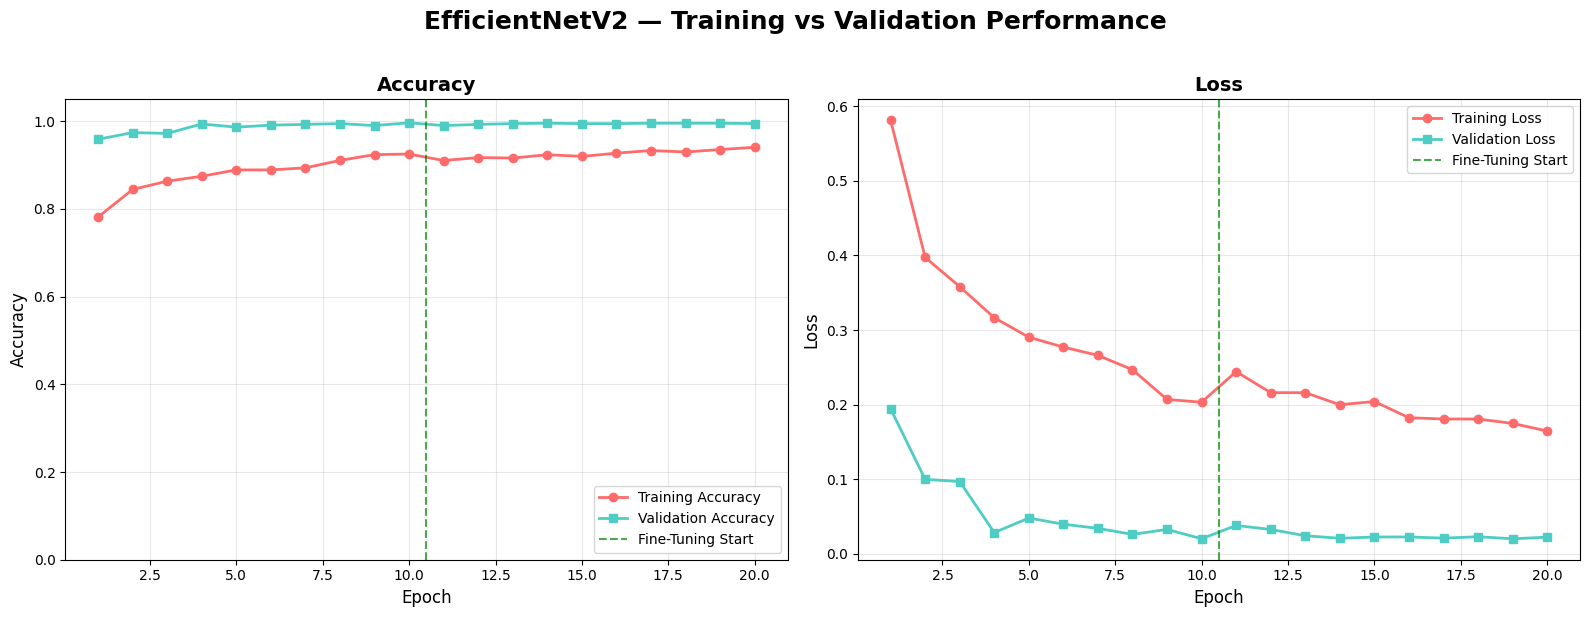

EfficientNetV2 — Final Training Accuracy: 94.06%
EfficientNetV2 — Final Validation Accuracy: 99.46%


In [19]:
# ========== EfficientNetV2: Training vs Validation Curves ==========

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('EfficientNetV2 — Training vs Validation Performance', fontsize=18, fontweight='bold', y=1.02)

epochs_range = range(1, len(eff_acc) + 1)
ft_start = len(eff_history_s1.history['accuracy']) + 0.5  # fine-tuning start point

# Accuracy
axes[0].plot(epochs_range, eff_acc, 'o-', color='#FF6B6B', linewidth=2, markersize=6, label='Training Accuracy')
axes[0].plot(epochs_range, eff_val_acc, 's-', color='#4ECDC4', linewidth=2, markersize=6, label='Validation Accuracy')
axes[0].axvline(x=ft_start, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[0].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=10, loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Loss
axes[1].plot(epochs_range, eff_loss_hist, 'o-', color='#FF6B6B', linewidth=2, markersize=6, label='Training Loss')
axes[1].plot(epochs_range, eff_val_loss, 's-', color='#4ECDC4', linewidth=2, markersize=6, label='Validation Loss')
axes[1].axvline(x=ft_start, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[1].set_title('Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(fontsize=10, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"EfficientNetV2 — Final Training Accuracy: {eff_acc[-1]*100:.2f}%")
print(f"EfficientNetV2 — Final Validation Accuracy: {eff_val_acc[-1]*100:.2f}%")

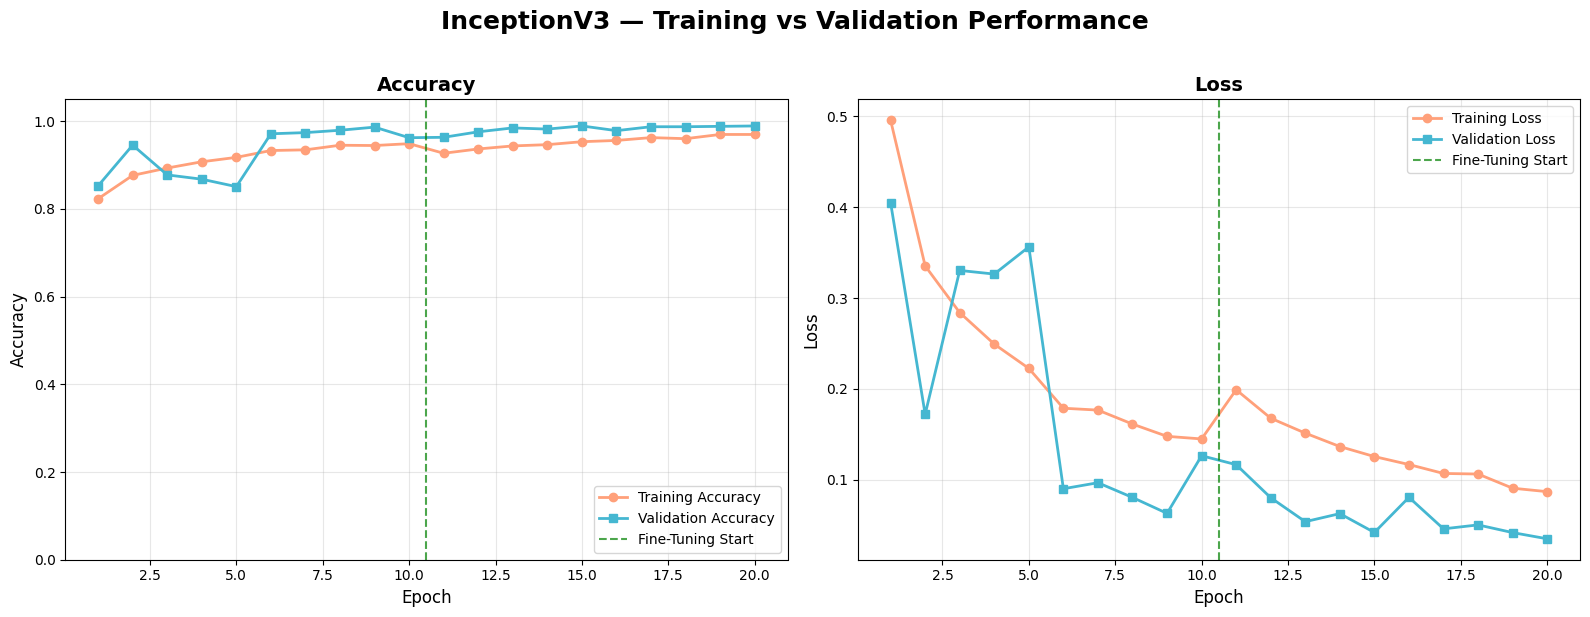

InceptionV3 — Final Training Accuracy: 96.99%
InceptionV3 — Final Validation Accuracy: 98.93%


In [20]:
# ========== InceptionV3: Training vs Validation Curves ==========

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('InceptionV3 — Training vs Validation Performance', fontsize=18, fontweight='bold', y=1.02)

epochs_range_inc = range(1, len(inc_acc) + 1)
ft_start_inc = len(inc_history_s1.history['accuracy']) + 0.5

# Accuracy
axes[0].plot(epochs_range_inc, inc_acc, 'o-', color='#FFA07A', linewidth=2, markersize=6, label='Training Accuracy')
axes[0].plot(epochs_range_inc, inc_val_acc, 's-', color='#45B7D1', linewidth=2, markersize=6, label='Validation Accuracy')
axes[0].axvline(x=ft_start_inc, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[0].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=10, loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Loss
axes[1].plot(epochs_range_inc, inc_loss_hist, 'o-', color='#FFA07A', linewidth=2, markersize=6, label='Training Loss')
axes[1].plot(epochs_range_inc, inc_val_loss, 's-', color='#45B7D1', linewidth=2, markersize=6, label='Validation Loss')
axes[1].axvline(x=ft_start_inc, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[1].set_title('Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(fontsize=10, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"InceptionV3 — Final Training Accuracy: {inc_acc[-1]*100:.2f}%")
print(f"InceptionV3 — Final Validation Accuracy: {inc_val_acc[-1]*100:.2f}%")

## Overfitting vs Underfitting Analysis

Niche training ar validation er moddhe gap (generalization gap) analyze kora hoyeche:
- **Underfitting:** Training accuracy o validation accuracy — duita-i kom thake. Model enough shikhte pareni.
- **Good Fit:** Training ar validation accuracy kachaakachi thake ar duita-i beshi.
- **Overfitting:** Training accuracy onek beshi kintu validation accuracy onek kom. Model training data mone rekheche, shikheni.

Orange shaded area = Generalization Gap (train ar val er difference)

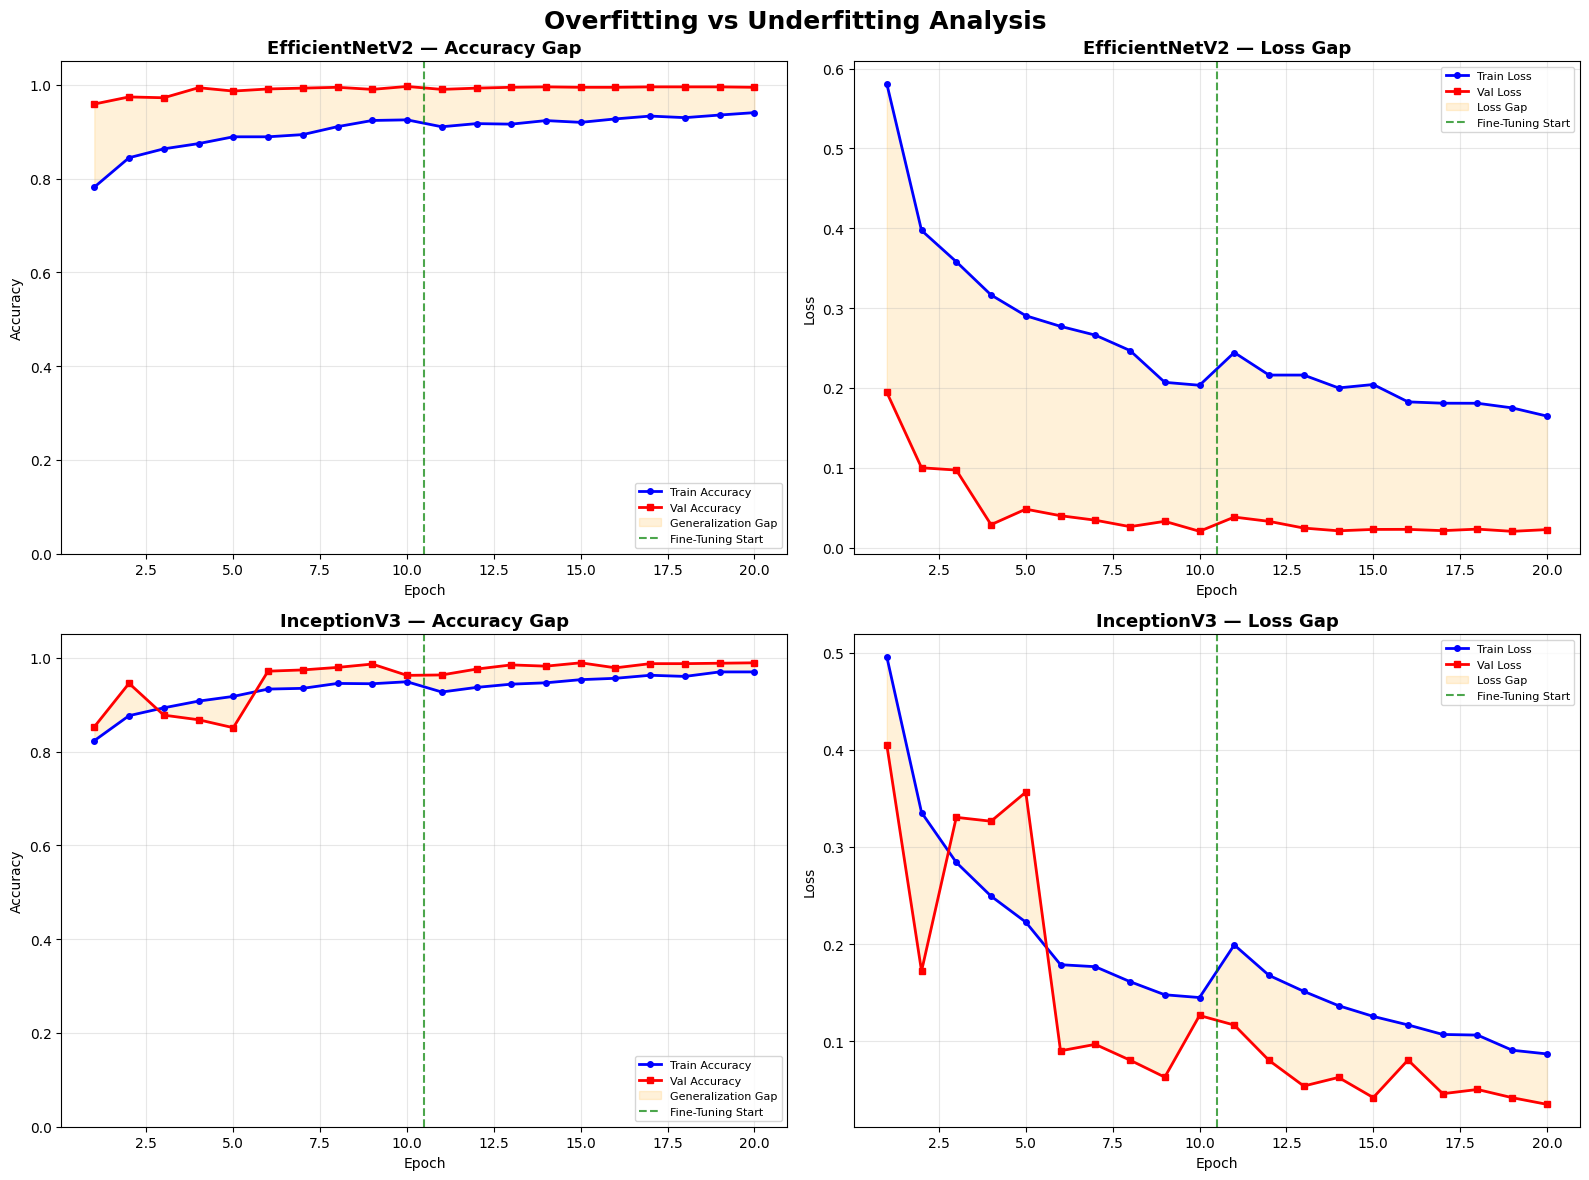

  OVERFITTING vs UNDERFITTING DIAGNOSIS
  EfficientNetV2: Train-Val Gap = -0.0540
  Status: ✅ Good Fit — training ar validation kachaakachi ache

  InceptionV3:    Train-Val Gap = -0.0194
  Status: ✅ Good Fit — training ar validation kachaakachi ache


In [22]:
# ========== Overfitting vs Underfitting Analysis ==========

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Overfitting vs Underfitting Analysis', fontsize=18, fontweight='bold')

# --- EfficientNetV2 Accuracy Gap ---
eff_epochs = range(1, len(eff_acc) + 1)
eff_ft = len(eff_history_s1.history['accuracy']) + 0.5

axes[0, 0].plot(eff_epochs, eff_acc, 'b-o', markersize=4, linewidth=2, label='Train Accuracy')
axes[0, 0].plot(eff_epochs, eff_val_acc, 'r-s', markersize=4, linewidth=2, label='Val Accuracy')
axes[0, 0].fill_between(eff_epochs, eff_acc, eff_val_acc, alpha=0.15, color='orange', label='Generalization Gap')
axes[0, 0].axvline(x=eff_ft, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[0, 0].set_title('EfficientNetV2 — Accuracy Gap', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=8, loc='lower right')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].set_ylim([0, 1.05])

# --- EfficientNetV2 Loss Gap ---
axes[0, 1].plot(eff_epochs, eff_loss_hist, 'b-o', markersize=4, linewidth=2, label='Train Loss')
axes[0, 1].plot(eff_epochs, eff_val_loss, 'r-s', markersize=4, linewidth=2, label='Val Loss')
axes[0, 1].fill_between(eff_epochs, eff_loss_hist, eff_val_loss, alpha=0.15, color='orange', label='Loss Gap')
axes[0, 1].axvline(x=eff_ft, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[0, 1].set_title('EfficientNetV2 — Loss Gap', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=8, loc='upper right')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')

# --- InceptionV3 Accuracy Gap ---
inc_epochs = range(1, len(inc_acc) + 1)
inc_ft = len(inc_history_s1.history['accuracy']) + 0.5

axes[1, 0].plot(inc_epochs, inc_acc, 'b-o', markersize=4, linewidth=2, label='Train Accuracy')
axes[1, 0].plot(inc_epochs, inc_val_acc, 'r-s', markersize=4, linewidth=2, label='Val Accuracy')
axes[1, 0].fill_between(inc_epochs, inc_acc, inc_val_acc, alpha=0.15, color='orange', label='Generalization Gap')
axes[1, 0].axvline(x=inc_ft, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[1, 0].set_title('InceptionV3 — Accuracy Gap', fontsize=13, fontweight='bold')
axes[1, 0].legend(fontsize=8, loc='lower right')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylim([0, 1.05])

# --- InceptionV3 Loss Gap ---
axes[1, 1].plot(inc_epochs, inc_loss_hist, 'b-o', markersize=4, linewidth=2, label='Train Loss')
axes[1, 1].plot(inc_epochs, inc_val_loss, 'r-s', markersize=4, linewidth=2, label='Val Loss')
axes[1, 1].fill_between(inc_epochs, inc_loss_hist, inc_val_loss, alpha=0.15, color='orange', label='Loss Gap')
axes[1, 1].axvline(x=inc_ft, color='green', linestyle='--', alpha=0.7, label='Fine-Tuning Start')
axes[1, 1].set_title('InceptionV3 — Loss Gap', fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=8, loc='upper right')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')

plt.tight_layout()
plt.show()

# Overfitting/Underfitting Diagnostic
print("=" * 60)
print("  OVERFITTING vs UNDERFITTING DIAGNOSIS")
print("=" * 60)

eff_gap = eff_acc[-1] - eff_val_acc[-1]
inc_gap = inc_acc[-1] - inc_val_acc[-1]

# EfficientNetV2
if eff_acc[-1] < 0.70 and eff_val_acc[-1] < 0.70:
    eff_status = "⚠️ Underfitting — model needs more training or capacity"
elif eff_gap > 0.10:
    eff_status = "🔴 Overfitting — train accuracy onek beshi but val accuracy kom"
elif eff_gap > 0.05:
    eff_status = "🟡 Slight Overfitting — gap ta ektu beshi, regularization barano dorkar"
else:
    eff_status = "✅ Good Fit — training ar validation kachaakachi ache"

# InceptionV3
if inc_acc[-1] < 0.70 and inc_val_acc[-1] < 0.70:
    inc_status = "⚠️ Underfitting — model needs more training or capacity"
elif inc_gap > 0.10:
    inc_status = "🔴 Overfitting — train accuracy onek beshi but val accuracy kom"
elif inc_gap > 0.05:
    inc_status = "🟡 Slight Overfitting — gap ta ektu beshi, regularization barano dorkar"
else:
    inc_status = "✅ Good Fit — training ar validation kachaakachi ache"

print(f"  EfficientNetV2: Train-Val Gap = {eff_gap:.4f}")
print(f"  Status: {eff_status}")
print(f"\n  InceptionV3:    Train-Val Gap = {inc_gap:.4f}")
print(f"  Status: {inc_status}")
print("=" * 60)

## EfficientNetV2 vs InceptionV3 — Accuracy Comparison
Niche duita model er training accuracy ar validation (testing) accuracy side by side compare kora hoyeche.

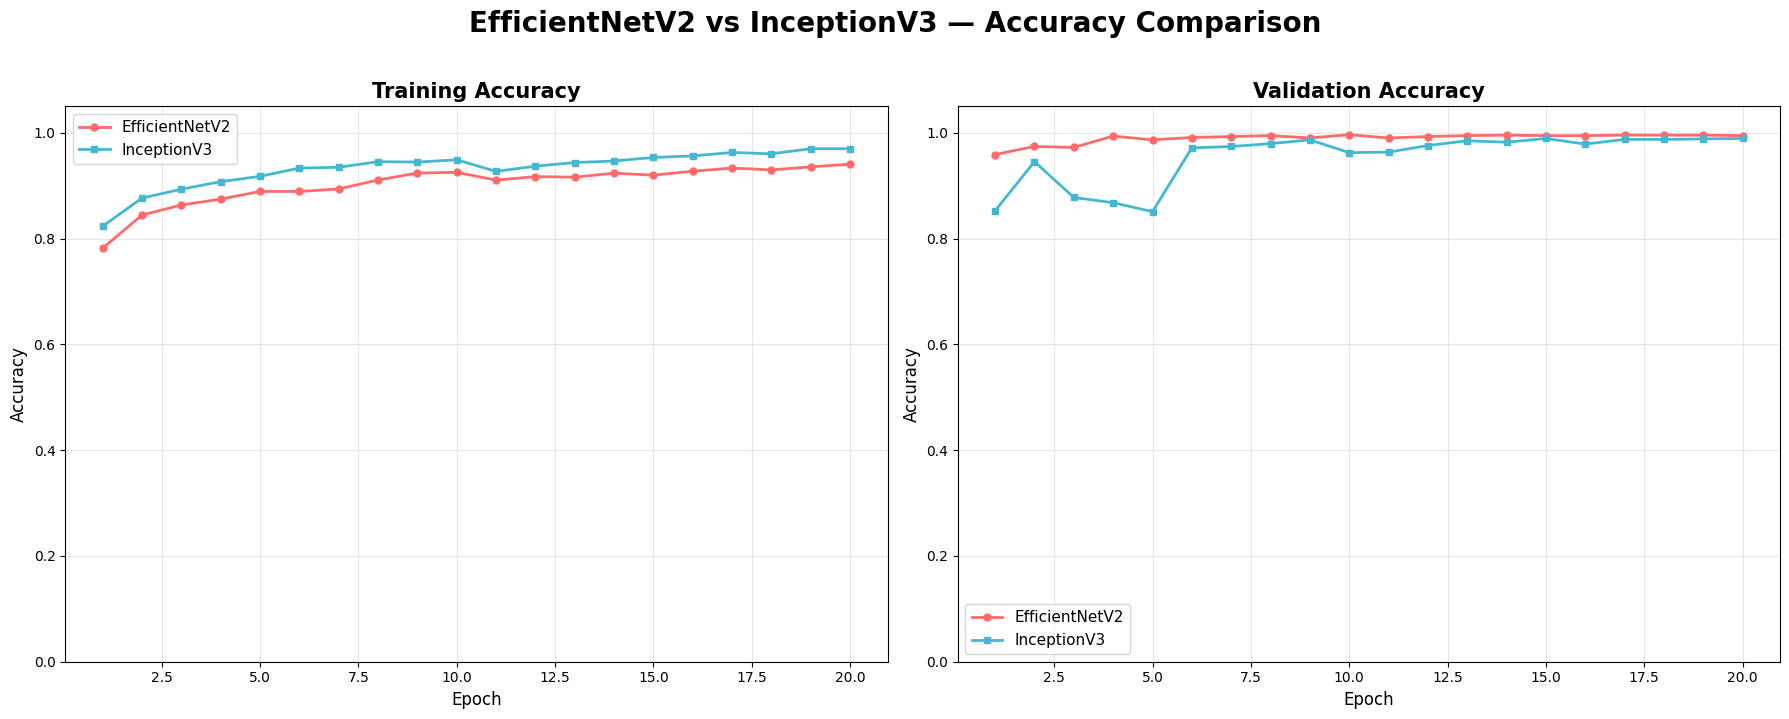

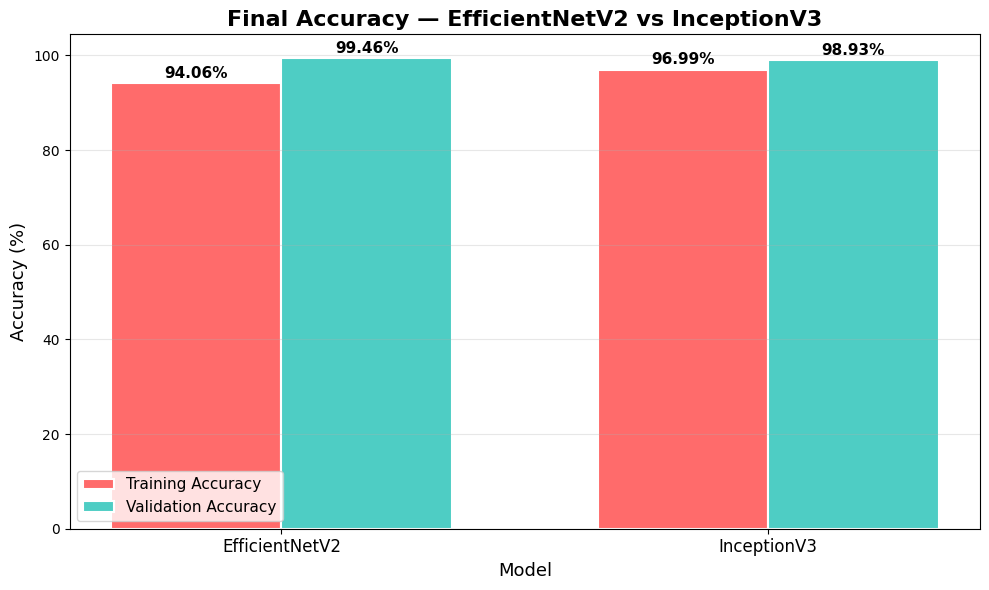


  MODEL ACCURACY COMPARISON SUMMARY
  EfficientNetV2 — Training Accuracy:   94.06%
  EfficientNetV2 — Validation Accuracy:  99.46%
  InceptionV3    — Training Accuracy:   96.99%
  InceptionV3    — Validation Accuracy:  98.93%
  ℹ️  Difference is very small (0.54%). Both models perform similarly.
  ℹ️  Per-class metrics (Recall, F1) o dekha dorkar to decide which is better.


In [24]:
# ========== EfficientNetV2 vs InceptionV3: Combined Accuracy Comparison ==========

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('EfficientNetV2 vs InceptionV3 — Accuracy Comparison', fontsize=20, fontweight='bold', y=1.02)

eff_ep = range(1, len(eff_acc) + 1)
inc_ep = range(1, len(inc_acc) + 1)

# Training Accuracy
axes[0].plot(eff_ep, eff_acc, 'o-', color='#FF6B6B', linewidth=2, markersize=5, label='EfficientNetV2')
axes[0].plot(inc_ep, inc_acc, 's-', color='#45B7D1', linewidth=2, markersize=5, label='InceptionV3')
axes[0].set_title('Training Accuracy', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Validation Accuracy
axes[1].plot(eff_ep, eff_val_acc, 'o-', color='#FF6B6B', linewidth=2, markersize=5, label='EfficientNetV2')
axes[1].plot(inc_ep, inc_val_acc, 's-', color='#45B7D1', linewidth=2, markersize=5, label='InceptionV3')
axes[1].set_title('Validation Accuracy', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

# ===== Final Accuracy Bar Chart =====
fig, ax = plt.subplots(figsize=(10, 6))

models_list = ['EfficientNetV2', 'InceptionV3']
train_accs = [eff_acc[-1] * 100, inc_acc[-1] * 100]
val_accs = [eff_val_acc[-1] * 100, inc_val_acc[-1] * 100]

x = np.arange(len(models_list))
width = 0.35

bars1 = ax.bar(x - width/2, train_accs, width, label='Training Accuracy', color='#FF6B6B', edgecolor='white', linewidth=1.5)
bars2 = ax.bar(x + width/2, val_accs, width, label='Validation Accuracy', color='#4ECDC4', edgecolor='white', linewidth=1.5)

ax.set_title('Final Accuracy — EfficientNetV2 vs InceptionV3', fontsize=16, fontweight='bold')
ax.set_xlabel('Model', fontsize=13)
ax.set_ylabel('Accuracy (%)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{height:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

# Print summary
print('\n' + '=' * 60)
print('  MODEL ACCURACY COMPARISON SUMMARY')
print('=' * 60)
print(f'  EfficientNetV2 — Training Accuracy:   {train_accs[0]:.2f}%')
print(f'  EfficientNetV2 — Validation Accuracy:  {val_accs[0]:.2f}%')
print(f'  InceptionV3    — Training Accuracy:   {train_accs[1]:.2f}%')
print(f'  InceptionV3    — Validation Accuracy:  {val_accs[1]:.2f}%')
print('=' * 60)

# shudhu accuracy dekhle cholbe na, difference onek kom hole seta mention korte hobe
diff = abs(val_accs[0] - val_accs[1])
if diff < 2.0:
    print(f'  ℹ️  Difference is very small ({diff:.2f}%). Both models perform similarly.')
    print(f'  ℹ️  Per-class metrics (Recall, F1) o dekha dorkar to decide which is better.')
elif val_accs[0] > val_accs[1]:
    print(f'  📊 EfficientNetV2 has higher validation accuracy by {diff:.2f}%')
else:
    print(f'  📊 InceptionV3 has higher validation accuracy by {diff:.2f}%')
print('=' * 60)

## Model Evaluation & Comparison (on Hold-out Test Set)

  HOLD-OUT TEST SET RESULTS


         Model Test Accuracy Test Loss
EfficientNetV2        87.63%    0.4247
   InceptionV3        90.25%    0.3969


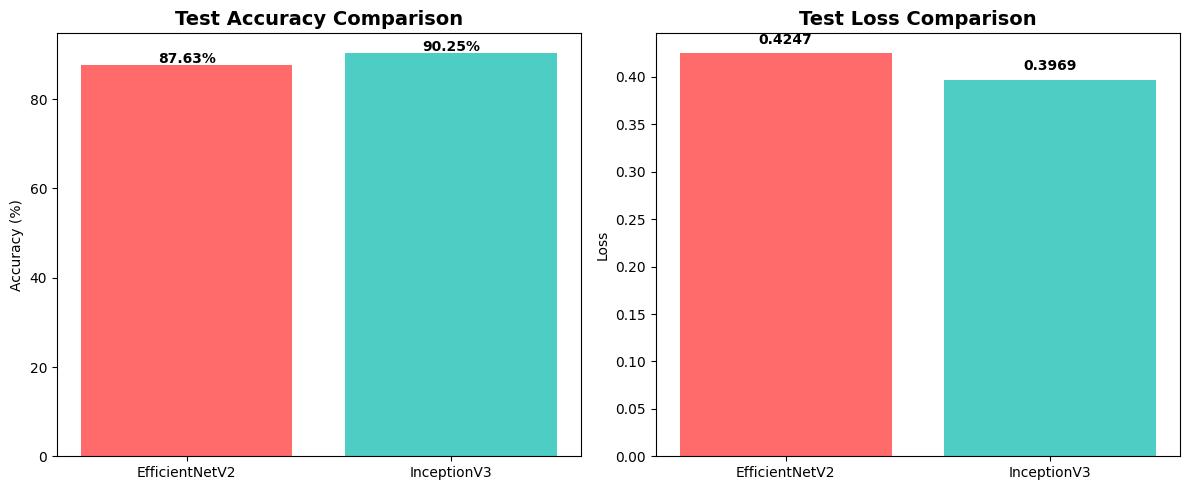

In [26]:
# Final evaluation — completely unseen test set er upor
# ei test data training ba validation er somoy kothao use hoyni

# EfficientNetV2 test results
eff_test_results = eff_model.evaluate(eff_test_ds, verbose=0)
inc_test_results = inception_model.evaluate(inc_test_ds, verbose=0)

comparison_df = pd.DataFrame({
    'Model': ['EfficientNetV2', 'InceptionV3'],
    'Test Accuracy': [f"{eff_test_results[1]*100:.2f}%", f"{inc_test_results[1]*100:.2f}%"],
    'Test Loss': [f"{eff_test_results[0]:.4f}", f"{inc_test_results[0]:.4f}"]
})
print("=" * 50)
print("  HOLD-OUT TEST SET RESULTS")
print("=" * 50)
print(comparison_df.to_string(index=False))
print("=" * 50)

# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
model_names = ['EfficientNetV2', 'InceptionV3']
test_accuracies = [eff_test_results[1] * 100, inc_test_results[1] * 100]
test_losses = [eff_test_results[0], inc_test_results[0]]

axes[0].bar(model_names, test_accuracies, color=['#FF6B6B', '#4ECDC4'])
axes[0].set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
for i, v in enumerate(test_accuracies):
    axes[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

axes[1].bar(model_names, test_losses, color=['#FF6B6B', '#4ECDC4'])
axes[1].set_title('Test Loss Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Loss')
for i, v in enumerate(test_losses):
    axes[1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

 1/50 ━━━━━━━━━━━━━━━━━━━━ 26:40 33s/step

 2/50 ━━━━━━━━━━━━━━━━━━━━ 2:20 3s/step  

 3/50 ━━━━━━━━━━━━━━━━━━━━ 2:17 3s/step

 4/50 ━━━━━━━━━━━━━━━━━━━━ 2:14 3s/step

 5/50 ━━━━━━━━━━━━━━━━━━━━ 2:11 3s/step

 6/50 ━━━━━━━━━━━━━━━━━━━━ 2:08 3s/step

... (41 outputs left out)

48/50 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step

49/50 ━━━━━━━━━━━━━━━━━━━━ 2s 3s/step

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step

50/50 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step


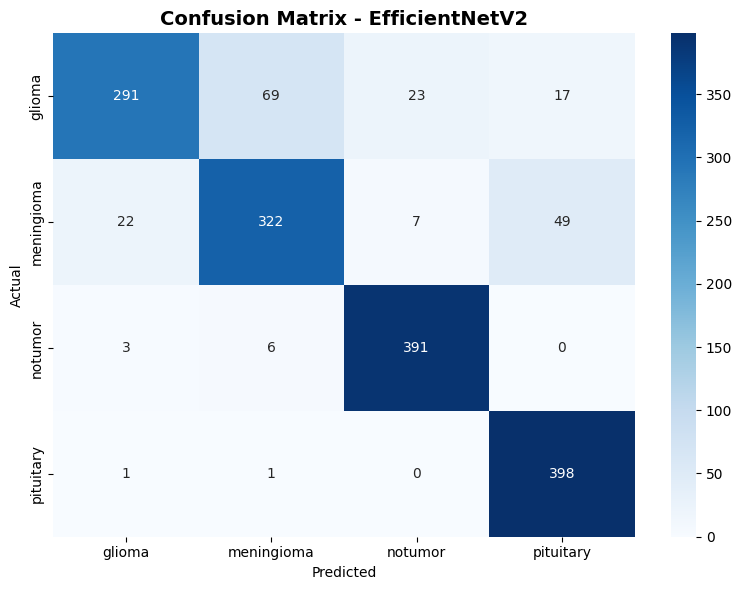


Classification Report — EfficientNetV2:
              precision    recall  f1-score   support

      glioma       0.92      0.73      0.81       400
  meningioma       0.81      0.81      0.81       400
     notumor       0.93      0.98      0.95       400
   pituitary       0.86      0.99      0.92       400

    accuracy                           0.88      1600
   macro avg       0.88      0.88      0.87      1600
weighted avg       0.88      0.88      0.87      1600



In [27]:
# Confusion Matrix & Classification Report — EfficientNetV2
# vectorized prediction — loop chalano dorkar nai, model.predict(dataset) ei dile hoy

eff_pred_probs = eff_model.predict(eff_test_ds)
eff_preds = np.argmax(eff_pred_probs, axis=1)

# labels gulo ekbare ber kora
eff_true_labels = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in eff_test_ds])

cm = confusion_matrix(eff_true_labels, eff_preds)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix - EfficientNetV2', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

print("\nClassification Report — EfficientNetV2:")
print(classification_report(eff_true_labels, eff_preds, target_names=CLASS_NAMES))

 1/50 ━━━━━━━━━━━━━━━━━━━━ 5:12 6s/step

 2/50 ━━━━━━━━━━━━━━━━━━━━ 1:03 1s/step

 3/50 ━━━━━━━━━━━━━━━━━━━━ 1:04 1s/step

 4/50 ━━━━━━━━━━━━━━━━━━━━ 1:03 1s/step

 5/50 ━━━━━━━━━━━━━━━━━━━━ 1:01 1s/step

 6/50 ━━━━━━━━━━━━━━━━━━━━ 1:00 1s/step

... (41 outputs left out)

48/50 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step

49/50 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step

50/50 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step


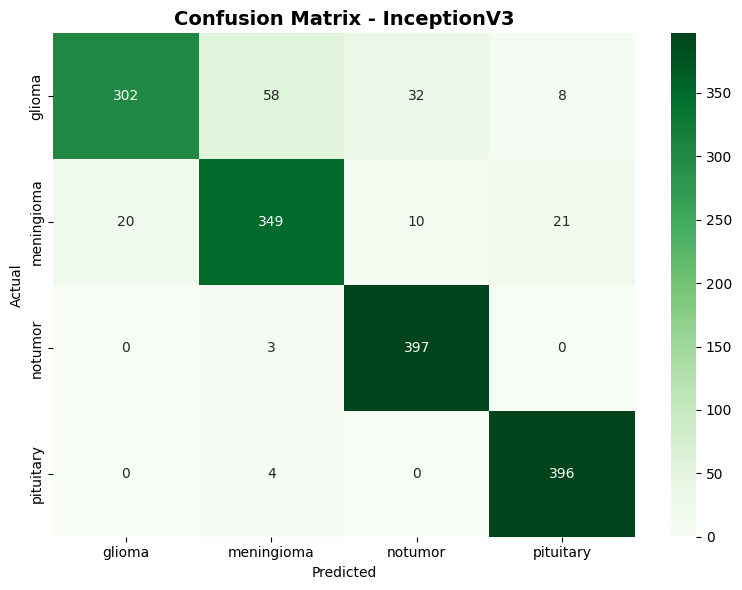


Classification Report — InceptionV3:
              precision    recall  f1-score   support

      glioma       0.94      0.76      0.84       400
  meningioma       0.84      0.87      0.86       400
     notumor       0.90      0.99      0.95       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.90      1600
weighted avg       0.90      0.90      0.90      1600



In [28]:
# Confusion Matrix & Classification Report — InceptionV3

inc_pred_probs = inception_model.predict(inc_test_ds)
inc_preds = np.argmax(inc_pred_probs, axis=1)

inc_true_labels = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in inc_test_ds])

cm_inc = confusion_matrix(inc_true_labels, inc_preds)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_inc, annot=True, fmt='d', cmap='Greens', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix - InceptionV3', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

print("\nClassification Report — InceptionV3:")
print(classification_report(inc_true_labels, inc_preds, target_names=CLASS_NAMES))

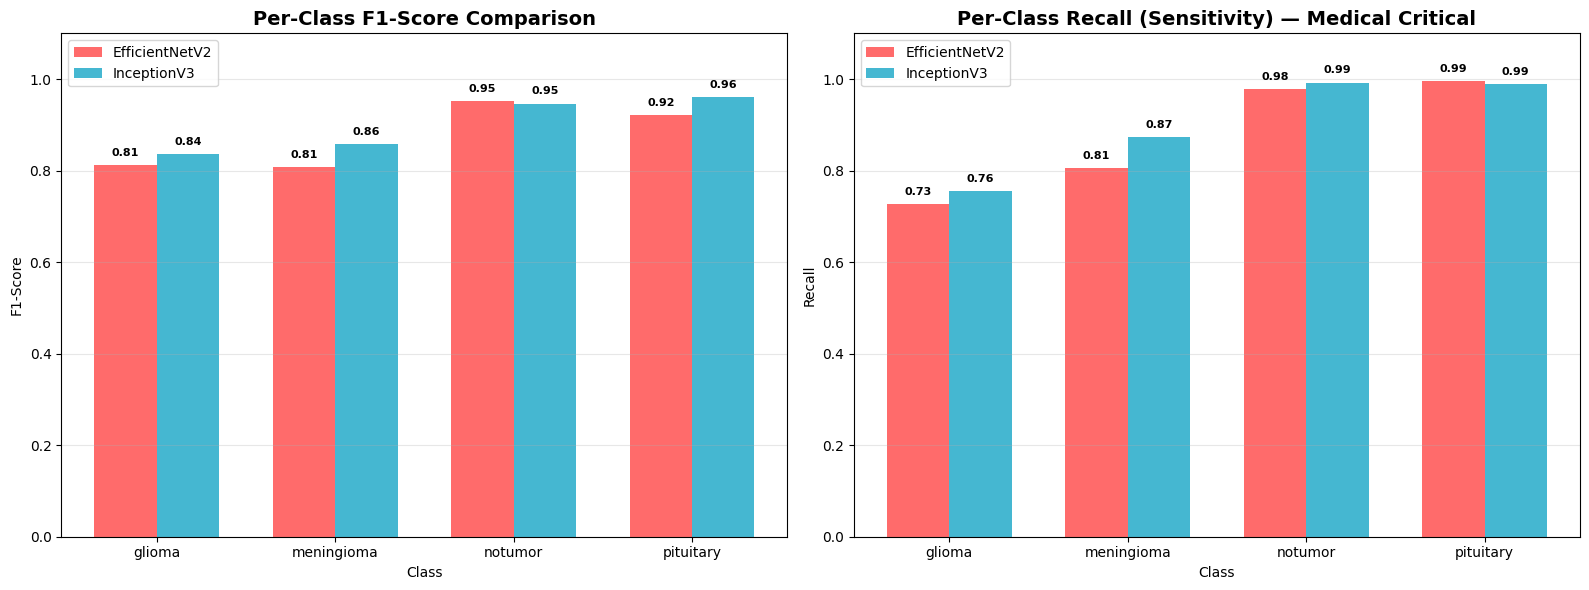


  PER-CLASS ANALYSIS (F1-Score)
        glioma: EfficientNetV2=0.812  InceptionV3=0.837  → InceptionV3
    meningioma: EfficientNetV2=0.807  InceptionV3=0.857  → InceptionV3
       notumor: EfficientNetV2=0.952  InceptionV3=0.946  → EfficientNetV2
     pituitary: EfficientNetV2=0.921  InceptionV3=0.960  → InceptionV3


In [29]:
# ========== Per-Class F1-Score Comparison ==========
# medical domain e overall accuracy theke per-class performance onek beshi important
# karon ekta class er bhul (e.g., glioma miss kora) life-threatening hote pare

from sklearn.metrics import f1_score, precision_score, recall_score

eff_f1 = f1_score(eff_true_labels, eff_preds, average=None)
inc_f1 = f1_score(inc_true_labels, inc_preds, average=None)
eff_recall = recall_score(eff_true_labels, eff_preds, average=None)
inc_recall = recall_score(inc_true_labels, inc_preds, average=None)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x = np.arange(NUM_CLASSES)
width = 0.35

# F1-Score comparison
axes[0].bar(x - width/2, eff_f1, width, label='EfficientNetV2', color='#FF6B6B')
axes[0].bar(x + width/2, inc_f1, width, label='InceptionV3', color='#45B7D1')
axes[0].set_title('Per-Class F1-Score Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('F1-Score')
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASS_NAMES, fontsize=10)
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1.1])

for i in range(NUM_CLASSES):
    axes[0].text(i - width/2, eff_f1[i] + 0.02, f'{eff_f1[i]:.2f}', ha='center', fontsize=8, fontweight='bold')
    axes[0].text(i + width/2, inc_f1[i] + 0.02, f'{inc_f1[i]:.2f}', ha='center', fontsize=8, fontweight='bold')

# Recall comparison — medical e ei metric ta shobcheye important
axes[1].bar(x - width/2, eff_recall, width, label='EfficientNetV2', color='#FF6B6B')
axes[1].bar(x + width/2, inc_recall, width, label='InceptionV3', color='#45B7D1')
axes[1].set_title('Per-Class Recall (Sensitivity) — Medical Critical', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Recall')
axes[1].set_xticks(x)
axes[1].set_xticklabels(CLASS_NAMES, fontsize=10)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1.1])

for i in range(NUM_CLASSES):
    axes[1].text(i - width/2, eff_recall[i] + 0.02, f'{eff_recall[i]:.2f}', ha='center', fontsize=8, fontweight='bold')
    axes[1].text(i + width/2, inc_recall[i] + 0.02, f'{inc_recall[i]:.2f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

# Per-class winner analysis
print("\n" + "=" * 60)
print("  PER-CLASS ANALYSIS (F1-Score)")
print("=" * 60)
for i, cls in enumerate(CLASS_NAMES):
    if eff_f1[i] > inc_f1[i]:
        better = "EfficientNetV2"
    elif inc_f1[i] > eff_f1[i]:
        better = "InceptionV3"
    else:
        better = "Tie"
    print(f"  {cls:>12s}: EfficientNetV2={eff_f1[i]:.3f}  InceptionV3={inc_f1[i]:.3f}  → {better}")
print("=" * 60)

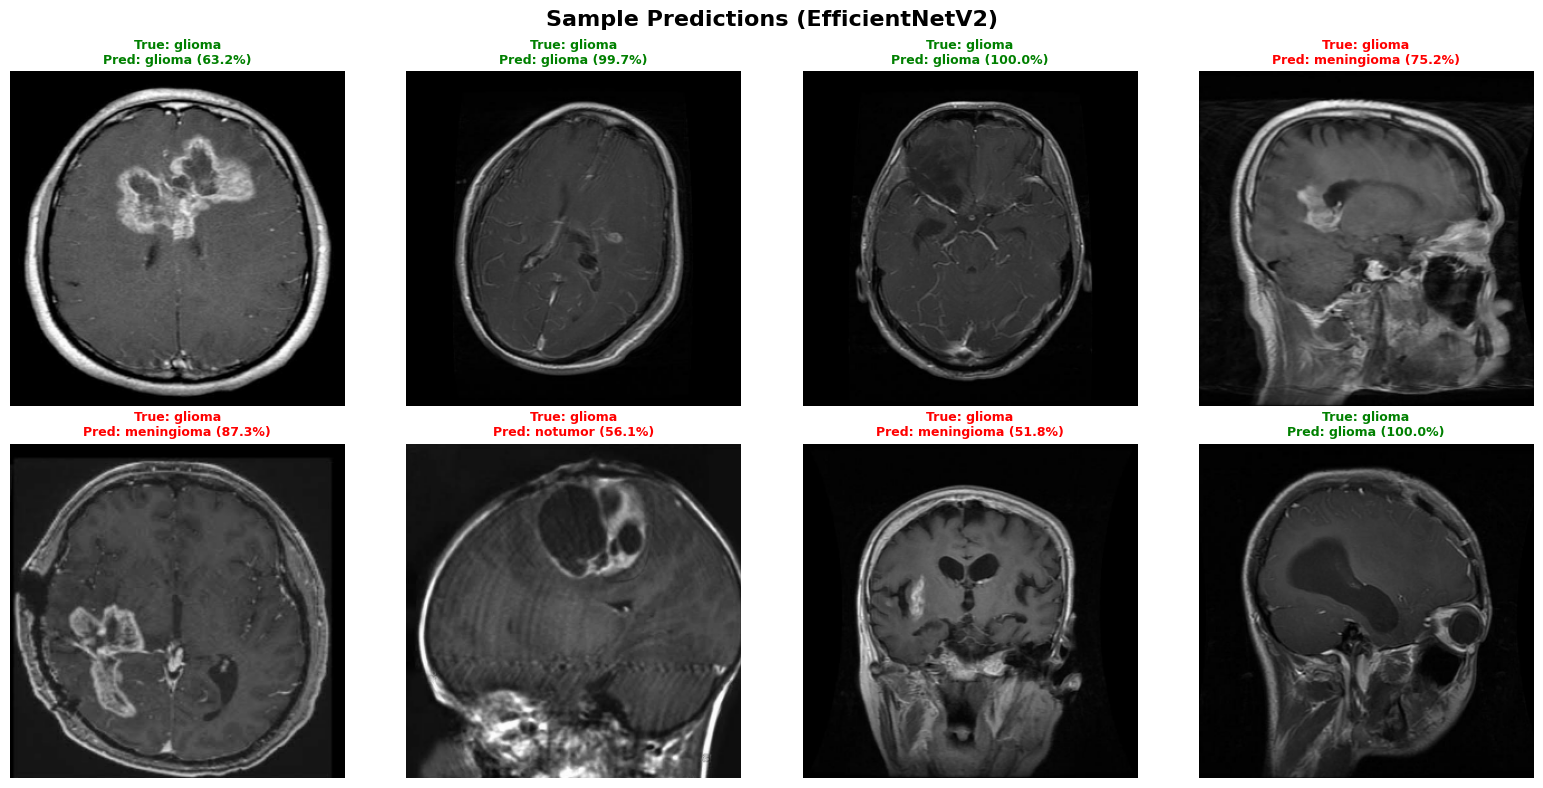

In [30]:
# Sample Predictions with Images — EfficientNetV2
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample Predictions (EfficientNetV2)', fontsize=16, fontweight='bold')

for images, labels in eff_test_ds.take(1):
    preds = eff_model.predict(images, verbose=0)
    for i in range(min(8, len(images))):
        row = i // 4
        col = i % 4
        axes[row, col].imshow(images[i].numpy().astype("uint8"))
        true_label = CLASS_NAMES[np.argmax(labels[i])]
        pred_label = CLASS_NAMES[np.argmax(preds[i])]
        confidence = np.max(preds[i]) * 100
        color = 'green' if true_label == pred_label else 'red'
        axes[row, col].set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
                                  fontsize=9, color=color, fontweight='bold')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

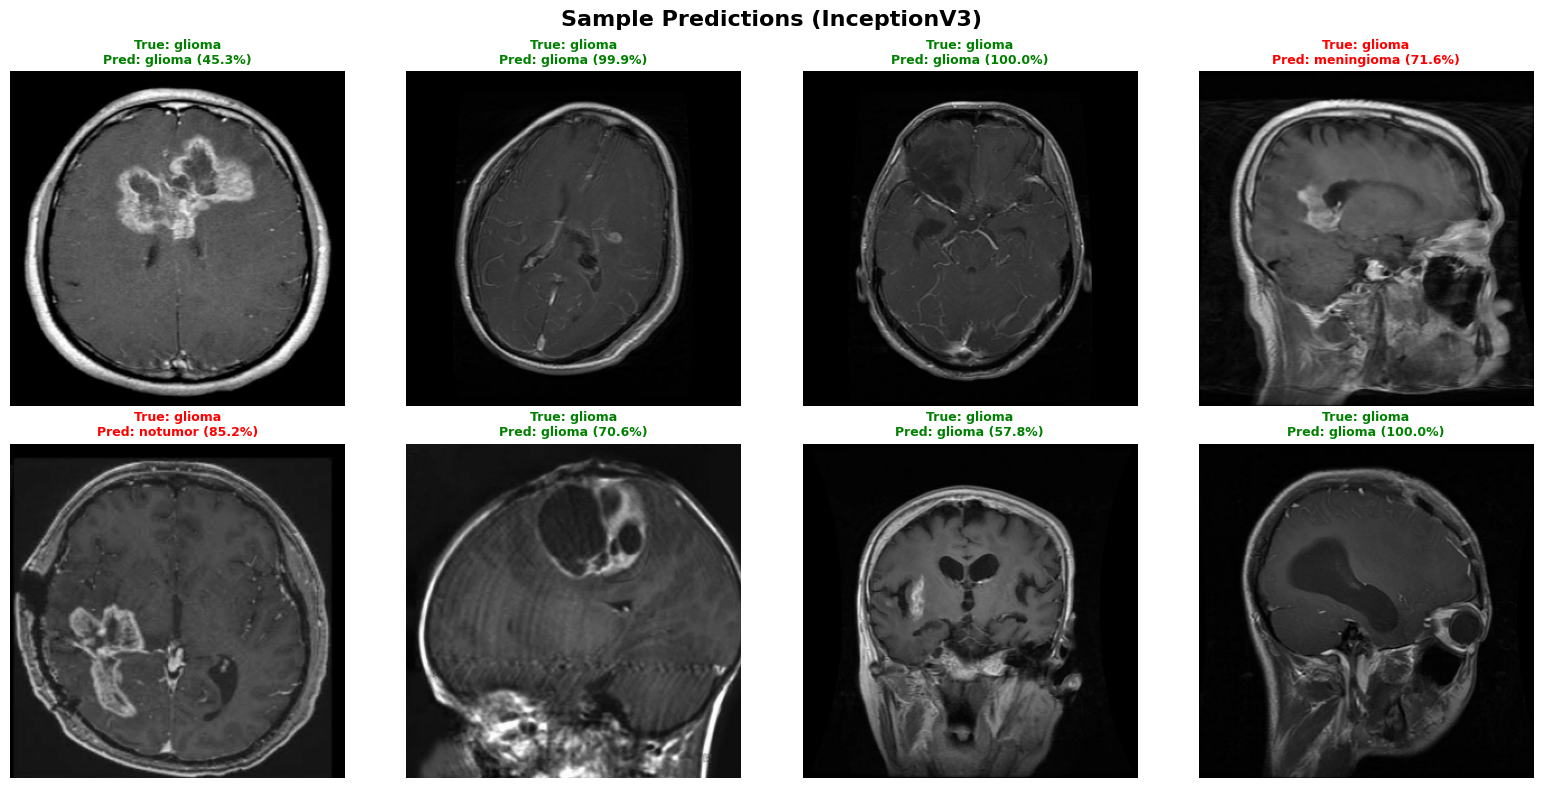


✅ All cells executed successfully!


In [31]:
# Sample Predictions with Images — InceptionV3
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sample Predictions (InceptionV3)', fontsize=16, fontweight='bold')

for images, labels in inc_test_ds.take(1):
    preds = inception_model.predict(images, verbose=0)
    for i in range(min(8, len(images))):
        row = i // 4
        col = i % 4
        axes[row, col].imshow(images[i].numpy().astype("uint8"))
        true_label = CLASS_NAMES[np.argmax(labels[i])]
        pred_label = CLASS_NAMES[np.argmax(preds[i])]
        confidence = np.max(preds[i]) * 100
        color = 'green' if true_label == pred_label else 'red'
        axes[row, col].set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
                                  fontsize=9, color=color, fontweight='bold')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

print("\n✅ All cells executed successfully!")